<a href="https://colab.research.google.com/github/Harikrishnan1104/basics.txt/blob/main/Tanglish_SHAP_Dashboard.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Step 1 — Install libraries

In [1]:
!pip install -q transformers datasets shap gradio sentencepiece protobuf accelerate scikit-learn

## Step 2 — Upload and clean the scraped data


In [2]:
import pandas as pd, re, torch
from google.colab import files

uploaded = files.upload()                      # pick your scraped CSV
fname = list(uploaded.keys())[0]
df = pd.read_csv(fname, encoding='utf-8')
print("Raw rows:", len(df))

def clean(t):
    t = str(t)
    t = t.replace('\r', ' ').replace('\n', ' ')
    t = re.sub(r'http\S+|www\.\S+', ' ', t)     # links
    t = re.sub(r'@[\w\-]+', ' ', t)              # @mentions
    t = re.sub(r'\s+', ' ', t).strip()
    return t

df['text'] = df['text'].apply(clean)
df = df[df['text'].str.count(r'[A-Za-z\u0B80-\u0BFF]') >= 5]   # drop emoji-only / tiny comments
df = df.drop_duplicates(subset='text').reset_index(drop=True)
print("Clean rows:", len(df))
df.sample(min(10, len(df)))

Saving tanglish_manual_checked.csv to tanglish_manual_checked.csv
Raw rows: 278
Clean rows: 266


,ID,text,source_url,category,manual_label
119,129,Yanaku yen da aluga varuthu 😫🥺,https://www.youtube.com/watch?v=3GEU31KUIzY,tanglish_translit,0
194,204,Anna no words evlo peru nambaluku irukom....Ne...,https://www.youtube.com/watch?v=3GEU31KUIzY,tanglish_translit,1
217,228,"17.42 true words, anna neenga health pathukonga",https://www.youtube.com/watch?v=3GEU31KUIzY,tanglish_translit,1
101,111,17:32 17:42 😢naa serious aa azhadethe pa 😢,https://www.youtube.com/watch?v=3GEU31KUIzY,tanglish_translit,1
125,135,“என்ன மயிரு வாழ்க்கை இது” to “அவர்தம் வாழ்வின்...,https://www.youtube.com/watch?v=3GEU31KUIzY,mixed_script,1
124,134,Yarum illa bro😂,https://www.youtube.com/watch?v=3GEU31KUIzY,tanglish_translit,1
141,151,Siddhu Anna azharathu Pakkum bothu automatic a...,https://www.youtube.com/watch?v=3GEU31KUIzY,tanglish_translit,1
206,216,The way anna emotion😭🫂,https://www.youtube.com/watch?v=3GEU31KUIzY,tanglish_translit,1
212,222,Nalla irunga ya ivulo manithargal manasula iru...,https://www.youtube.com/watch?v=3GEU31KUIzY,tanglish_translit,1
66,73,​ ila sirichtu irupan bagavanth kesari padatho...,https://www.youtube.com/watch?v=fJaAYcERf3Y&t=2s,tanglish_translit,1


In [3]:
from datasets import load_dataset, concatenate_datasets

scraped_df = df.copy()   # keep YOUR scraped comments for testing later

raw = load_dataset("community-datasets/tamilmixsentiment")
full = concatenate_datasets([raw[s] for s in raw.keys()])
text_col = [c for c, f in full.features.items() if getattr(f, "dtype", None) == "string"][0]
names = full.features["label"].names
print("Original labels:", names)

# keep 3 clear classes, drop "Mixed_feelings" and "not-Tamil"
mapping = {"Positive": "positive", "Negative": "negative", "unknown_state": "neutral"}
df = full.to_pandas().rename(columns={text_col: "text"})
df["label"] = df["label"].map(lambda i: mapping.get(names[i]))
df = df.dropna(subset=["label"])[["text", "label"]]
df["text"] = df["text"].apply(clean)
df = df[df["text"].str.len() > 3].drop_duplicates("text").reset_index(drop=True)

print("Training data size:", len(df))
print(df["label"].value_counts())

README.md:   0%|          | 0.00/9.35k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  507kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 60.3kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/11335 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1260 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3149 [00:00<?, ? examples/s]

Original labels: ['Positive', 'Negative', 'Mixed_feelings', 'unknown_state', 'not-Tamil']
Training data size: 13308
label
positive    10434
negative     2028
neutral       846
Name: count, dtype: int64


## Step 3 — Auto-label sentiment (weak labels)


In [ ]:
from transformers import pipeline

device = 0 if torch.cuda.is_available() else -1
labeler = pipeline("sentiment-analysis",
                   model="cardiffnlp/twitter-xlm-roberta-base-sentiment",
                   device=device, truncation=True, max_length=128)

preds = labeler(df['text'].tolist(), batch_size=32)
df['label'] = [p['label'].lower() for p in preds]
df['label_confidence'] = [round(p['score'], 3) for p in preds]

# keep only the labels the labeler was reasonably sure about
df = df[df['label_confidence'] >= 0.5].reset_index(drop=True)
print(df['label'].value_counts())

df.to_csv('tanglish_labeled.csv', index=False, encoding='utf-8-sig')
files.download('tanglish_labeled.csv')

## Step 4 — Fine-tune IndicBERT


In [6]:
import numpy as np
import torch
from torch import nn
from datasets import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)

MODEL_NAME = "ai4bharat/IndicBERTv2-MLM-only"
label2id = {"negative": 0, "neutral": 1, "positive": 2}
id2label = {v: k for k, v in label2id.items()}

df['labels'] = df['label'].map(label2id)
train_df, test_df = train_test_split(df[['text', 'labels']], test_size=0.2,
                                     stratify=df['labels'], random_state=42)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
def tok(batch):
    return tokenizer(batch['text'], truncation=True, max_length=128)

train_ds = Dataset.from_pandas(train_df.reset_index(drop=True)).map(tok, batched=True)
test_ds  = Dataset.from_pandas(test_df.reset_index(drop=True)).map(tok, batched=True)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=3, id2label=id2label, label2id=label2id)

# Give rarer classes (negative/neutral) more weight so the model can't just say "positive"
counts = train_df['labels'].value_counts().reindex(range(3), fill_value=1).sort_index()
class_weights = torch.tensor((len(train_df) / (3 * counts)).values, dtype=torch.float)
print("Class weights (neg, neu, pos):", class_weights.tolist())

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss_fn = nn.CrossEntropyLoss(weight=class_weights.to(outputs.logits.device))
        loss = loss_fn(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

def compute_metrics(p):
    preds = np.argmax(p.predictions, axis=1)
    return {"accuracy": accuracy_score(p.label_ids, preds),
            "f1_macro": f1_score(p.label_ids, preds, average="macro")}

args = TrainingArguments(
    output_dir="indicbert-tanglish",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=3e-5,

    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    save_total_limit=1,
    fp16=torch.cuda.is_available(),
    report_to="none",
)

trainer = WeightedTrainer(model=model, args=args, train_dataset=train_ds, eval_dataset=test_ds,
                          data_collator=DataCollatorWithPadding(tokenizer),
                          compute_metrics=compute_metrics)
trainer.train()

out = trainer.predict(test_ds)
print(classification_report(out.label_ids, np.argmax(out.predictions, axis=1),
                            target_names=list(label2id.keys()), zero_division=0))

trainer.save_model("indicbert-tanglish-final")
tokenizer.save_pretrained("indicbert-tanglish-final")

Map:   0%|          | 0/10646 [00:00<?, ? examples/s]

Map:   0%|          | 0/2662 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: ai4bharat/IndicBERTv2-MLM-only
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those p

Class weights (neg, neu, pos): [2.1878340244293213, 5.241752624511719, 0.425142765045166]


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

              precision    recall  f1-score   support

    negative       0.33      0.52      0.41       406
     neutral       0.17      0.34      0.23       169
    positive       0.87      0.70      0.78      2087

    accuracy                           0.65      2662
   macro avg       0.46      0.52      0.47      2662
weighted avg       0.74      0.65      0.69      2662



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('indicbert-tanglish-final/tokenizer_config.json',
 'indicbert-tanglish-final/tokenizer.json')

## Step 5 — Plug the trained model into SHAP


In [8]:
import shap
import torch
from transformers import pipeline

device = 0 if torch.cuda.is_available() else -1

clf = pipeline("text-classification", model="indicbert-tanglish-final",
               tokenizer="indicbert-tanglish-final", device=device, top_k=None,
               truncation=True, max_length=128)
explainer = shap.Explainer(clf)

sv = explainer(["intha padam semma mass da", "acting mokka but songs super"])
shap.plots.text(sv[0])

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


## Step 6 — (Optional) Which words drive the model overall?


  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer:  10%|█         | 6/60 [00:18<01:52,  2.09s/it]

  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer:  13%|█▎        | 8/60 [00:25<02:19,  2.68s/it]

  0%|          | 0/498 [00:00<?, ?it/s]

...

PartitionExplainer explainer:  90%|█████████ | 54/60 [02:45<00:19,  3.18s/it]

  0%|          | 0/462 [00:00<?, ?it/s]

PartitionExplainer explainer:  95%|█████████▌| 57/60 [02:53<00:07,  2.38s/it]

  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer: 61it [03:06,  3.21s/it]


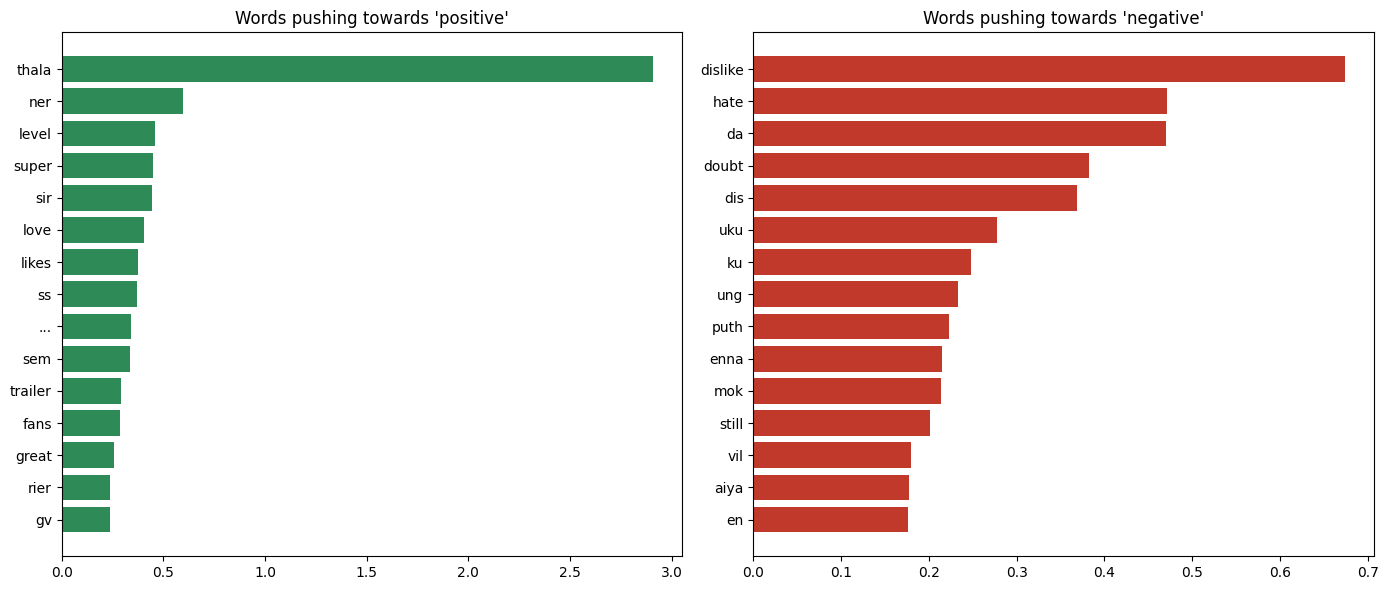

In [9]:
import matplotlib.pyplot as plt
from collections import defaultdict

sample_texts = test_df['text'].tolist()[:60]
sv_all = explainer(sample_texts)

def top_words(class_name, k=15):
    idx = list(sv_all.output_names).index(class_name)
    scores = defaultdict(float)
    for i in range(len(sample_texts)):
        for tokn, val in zip(sv_all[i].data, sv_all[i].values[:, idx]):
            w = tokn.strip().lower()
            if len(w) > 1:
                scores[w] += val
    return sorted(scores.items(), key=lambda x: x[1], reverse=True)[:k]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, cls, col in zip(axes, ["positive", "negative"], ["#2e8b57", "#c0392b"]):
    words, vals = zip(*top_words(cls))
    ax.barh(words[::-1], vals[::-1], color=col)
    ax.set_title(f"Words pushing towards '{cls}'")
plt.tight_layout(); plt.show()

## Step 7 — Launch the dashboard


In [ ]:
import gradio as gr
import html as html_lib

CLASSES = ["negative", "neutral", "positive"]

def colour_tokens(tokens, values):
    m = max(abs(values).max(), 1e-6)
    spans = []
    for t, v in zip(tokens, values):
        a = min(abs(v) / m, 1.0) * 0.85
        rgb = "46,139,87" if v > 0 else "192,57,43"   # green = supports, red = goes against
        spans.append(f'<span title="{v:+.3f}" style="background:rgba({rgb},{a:.2f});'
                     f'padding:2px 1px;border-radius:4px">{html_lib.escape(t)}</span>')
    return ('<div style="font-size:22px;line-height:2.2">' + "".join(spans) + '</div>'
            '<p style="font-size:13px;opacity:.75">Green = word pushed the model '
            '<b>towards</b> this label · Red = pushed it <b>away</b> · darker = stronger. '
            'Hover a word to see its SHAP value.</p>')

def bar_chart(tokens, values, label):
    pairs = [(t.strip(), v) for t, v in zip(tokens, values) if t.strip()]
    pairs = sorted(pairs, key=lambda x: abs(x[1]), reverse=True)[:10][::-1]
    fig, ax = plt.subplots(figsize=(6, 4))
    if pairs:
        w, v = zip(*pairs)
        ax.barh(w, v, color=["#2e8b57" if x > 0 else "#c0392b" for x in v])
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_title(f"Top words for '{label}'"); ax.set_xlabel("SHAP value")
    plt.tight_layout()
    return fig

def explain(text, target):
    text = (text or "").strip()
    if not text:
        return {}, "<p>Type a sentence first.</p>", None
    scores = {d['label']: d['score'] for d in clf(text)[0]}
    predicted = max(scores, key=scores.get)
    label = predicted if target == "Predicted label" else target
    s = explainer([text])[0]
    idx = list(s.output_names).index(label)
    vals = s.values[:, idx]
    head = f"<h3>Explaining: <i>{label}</i>" + (" (model's prediction)" if label == predicted else "") + "</h3>"
    return scores, head + colour_tokens(s.data, vals), bar_chart(s.data, vals, label)

examples = [["intha padam semma mass da", "Predicted label"],
            ["acting mokka aa iruku but songs super", "Predicted label"],
            ["vera level bro, thalaivar entry goosebumps", "Predicted label"],
            ["waste of time, story onnume illa", "Predicted label"]]

with gr.Blocks(title="Tanglish SHAP Explainer") as demo:
    gr.Markdown("# 🔍 Tanglish Sentiment — Explained with SHAP\n"
                "IndicBERT fine-tuned on scraped Tamil–English YouTube comments. "
                "Type a sentence to see the prediction **and which words caused it**.")
    with gr.Row():
        with gr.Column(scale=2):
            inp = gr.Textbox(label="Tanglish sentence", lines=3,
                             placeholder="e.g. intha padam semma mass da")
            tgt = gr.Radio(["Predicted label"] + CLASSES, value="Predicted label",
                           label="Explain which label?")
            btn = gr.Button("Explain", variant="primary")
        with gr.Column(scale=1):
            out_label = gr.Label(label="Prediction (confidence)", num_top_classes=3)
    out_html = gr.HTML()
    out_plot = gr.Plot(label="Word importance")
    gr.Examples(examples, inputs=[inp, tgt])
    btn.click(explain, [inp, tgt], [out_label, out_html, out_plot])

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://91535eb1a371902328.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
